# 03_feature_engineering.ipynb
Notebook này thực hiện quy trình tạo đặc trưng mới, đánh giá tương quan thực tế để làm cơ sở chọn lọc, sau đó loại bỏ các cột không hiệu quả và các cột vô dụng (SHAP = 0).

## 1. Import libraries và đọc dữ liệu sạch

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

In [2]:
df = pd.read_csv("../data/processed/train_clean.csv", keep_default_na=False)
df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,4.189655,9.042040,Pave,NA,Reg,Lvl,AllPub,Inside,...,0.0,NA,NA,NA,0.0,2,2008,WD,Normal,12.247699
1,20,RL,4.394449,9.169623,Pave,NA,Reg,Lvl,AllPub,FR2,...,0.0,NA,NA,NA,0.0,5,2007,WD,Normal,12.109016
2,60,RL,4.234107,9.328212,Pave,NA,IR1,Lvl,AllPub,Inside,...,0.0,NA,NA,NA,0.0,9,2008,WD,Normal,12.317171
3,70,RL,4.110874,9.164401,Pave,NA,IR1,Lvl,AllPub,Corner,...,0.0,NA,NA,NA,0.0,2,2006,WD,Abnorml,11.849405
4,60,RL,4.442651,9.565284,Pave,NA,IR1,Lvl,AllPub,FR2,...,0.0,NA,NA,NA,0.0,12,2008,WD,Normal,12.429220


## 2. Đưa các cột diện tích về đơn vị gốc
Các cột diện tích đã được lấy log1p ở notebook 01. Để cộng dồn hoặc chia tỷ lệ chính xác, ta dùng `expm1` để đưa về đơn vị diện tích thực tế trước khi tính toán.

In [3]:
log_cols = ["LotArea", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "GrLivArea", "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]
original = np.expm1(df[log_cols]).round()

## 3. Tạo các đặc trưng mới
Tạo các cột mới tự nhiên hơn mà những người đánh giá nhà hay để ý đến.

In [4]:
df["TotalSF"] = np.log1p(original["TotalBsmtSF"] + original["1stFlrSF"] + original["2ndFlrSF"])
df["TotalPorchSF"] = np.log1p(original[["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]].sum(axis=1))
df["TotalBath"] = df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
df["AreaPerRoom"] = np.log1p(original["GrLivArea"] / df["TotRmsAbvGrd"])
df["LotCoverage"] = original["1stFlrSF"] / original["LotArea"]
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]
df["IsRemodeled"] = (df["YearRemodAdd"] != df["YearBuilt"]).astype(int)

df["HasEnclosedPorch"] = (df["EnclosedPorch"] > 0).astype(int)
df["HasScreenPorch"] = (df["ScreenPorch"] > 0).astype(int)
df["HasWoodDeck"] = (df["WoodDeckSF"] > 0).astype(int)

## 4. Đo lường tương quan thực tế
Tính toán và ghi nhận mức độ tương quan của từng đặc trưng vừa tạo với SalePrice.

In [5]:
new_features = [
    "TotalSF", "TotalPorchSF", "TotalBath", "AreaPerRoom", "LotCoverage",
    "HouseAge", "RemodAge", "IsRemodeled", "HasEnclosedPorch", "HasScreenPorch", "HasWoodDeck"
]
print(df[new_features + ["SalePrice"]].corr()["SalePrice"].sort_values(ascending=False))

SalePrice           1.000000
TotalSF             0.807140
TotalBath           0.673011
AreaPerRoom         0.576017
HasWoodDeck         0.320349
TotalPorchSF        0.309608
HasScreenPorch      0.099436
LotCoverage        -0.023396
IsRemodeled        -0.073761
HasEnclosedPorch   -0.216559
RemodAge           -0.568136
HouseAge           -0.587290
Name: SalePrice, dtype: float64


## 5. Chọn lọc đặc trưng và loại bỏ các cột vô dụng
Chọn lọc dựa trên kết quả đo lường thực nghiệm ở bước 4 và phân tích SHAP.

In [6]:
drop_cols = [
    "LotCoverage", "IsRemodeled",
    "PoolArea", "PoolQC", "MiscVal", "MiscFeature", "3SsnPorch",
    "LowQualFinSF", "BsmtFinSF2", "BsmtHalfBath", "KitchenAbvGr",
    "Functional", "GarageQual", "GarageCond", "BldgType", "RoofMatl",
    "Utilities", "LandContour", "Street", "Alley", "Condition2",
    "Condition1", "LandSlope", "Heating", "BsmtCond", "MSZoning",
    "LotShape", "ExterCond", "MasVnrType", "Electrical", "BsmtFinType2",
    "RoofStyle", "PavedDrive", "Fence", "YrSold", "MoSold", "SaleType"
]
df = df.drop(columns=drop_cols)

## 6. Phân phối sau khi tinh giản
Vẽ biểu đồ histogram cho các đặc trưng số mới.

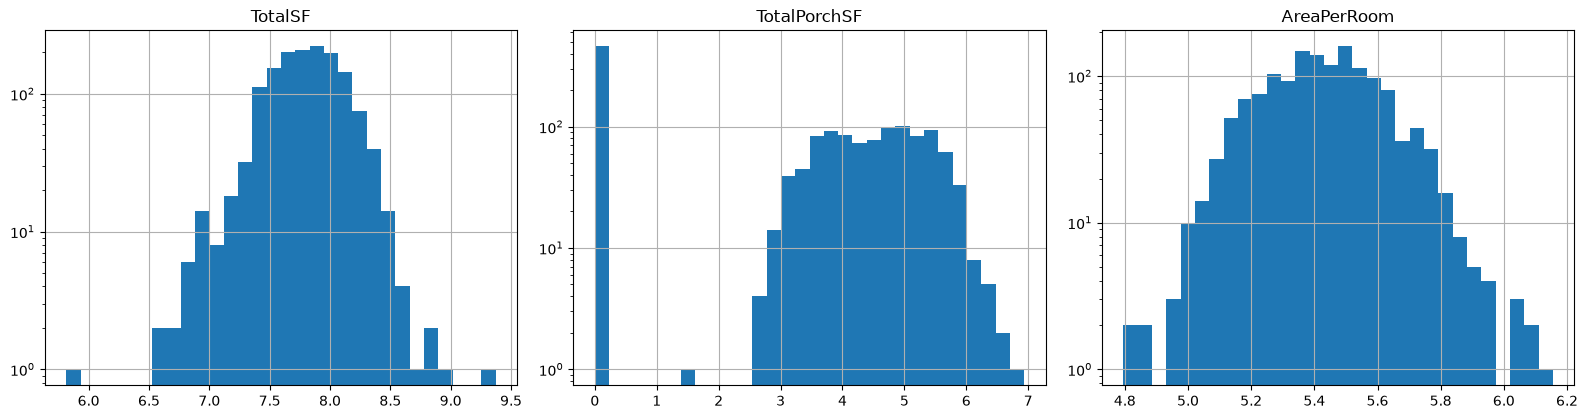

In [8]:
numeric_kept = ["TotalSF", "TotalPorchSF", "AreaPerRoom"]
df[numeric_kept].hist(bins=30, figsize=(16, 8), layout=(2, 3), log=True)
plt.tight_layout()
plt.show()

## 7. Xuất dữ liệu
Lưu dataframe tinh gọn ra file để sẵn sàng cho bước huấn luyện mô hình.

In [10]:
os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/train_features.csv", index=False)